# Experiment 1: Dataset inspection

Số samples: 50000
Số classes: 2

Phân bố lớp:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Missing text: 0
Missing labels: 0
Duplicate documents: 419

Thống kê độ dài chuỗi:
Minimum: 6
Median: 173.0
Mean: 230.9284
Maximum: 2473
P90 = 451; dài hơn ngưỡng: 9.96%
P95 = 588; dài hơn ngưỡng: 4.99%
P99 = 902; dài hơn ngưỡng: 1.00%


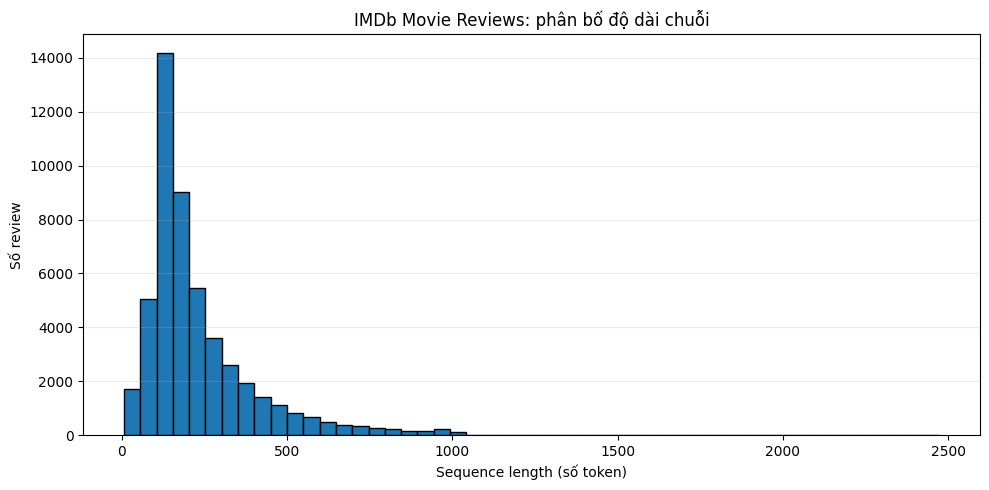

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import re
import html

path = "/home/vitquay1708/Study_Space/NLP/lab4/imdb/IMDB Dataset.csv"
df = pd.read_csv(path)
df["review_clean"] = (
    df["review"]
    .fillna("")
    .map(html.unescape)
    .str.replace(r"<[^>]+>", " ", regex=True)
    .str.strip()
    .str.lower()
)
token_pattern = re.compile(r"\b[\w]+(?:['’][\w]+)?\b", re.UNICODE)
df["sequence_length"] = df["review_clean"].map(
    lambda text: len(token_pattern.findall(text))
)
print("Số samples:", len(df))
print("Số classes:", df["sentiment"].nunique())
print("\nPhân bố lớp:")
print(df["sentiment"].value_counts(dropna=False))

print("\nMissing text:", df["review"].isna().sum() +
      df["review"].fillna("").str.strip().eq("").sum())
print("Missing labels:", df["sentiment"].isna().sum() +
      df["sentiment"].fillna("").str.strip().eq("").sum())

print("Duplicate documents:", df["review_clean"].duplicated().sum())

lengths = df.loc[df["review_clean"].ne(""), "sequence_length"]

print("\nThống kê độ dài chuỗi:")
print("Minimum:", lengths.min())
print("Median:", lengths.median())
print("Mean:", lengths.mean())
print("Maximum:", lengths.max())
for p in (0.90, 0.95, 0.99):
    max_length = int(lengths.quantile(p, interpolation="higher"))
    truncated_pct = lengths.gt(max_length).mean() * 100
    print(f"P{int(p * 100)} = {max_length}; dài hơn ngưỡng: {truncated_pct:.2f}%")

plt.figure(figsize=(10, 5))
plt.hist(lengths, bins=50, edgecolor="black")
plt.xlabel("Sequence length (số token)")
plt.ylabel("Số review")
plt.title("IMDb Movie Reviews: phân bố độ dài chuỗi")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig("imdb_sequence_length_histogram.png", dpi=150)
plt.show()

# Experiment 2: Padding và truncation

## 2.1. Phân tích độ dài gốc

Dùng `review_clean`, `token_pattern` và `sequence_length` của Experiment 1. Tách tập test theo cùng chỉ số và `random_state=42` như baseline bên dưới; tách thêm validation từ tập train. Tất cả độ dài dùng chung các tập này. Tỷ lệ giữ token và tỷ lệ review bị cắt được tính trên **tập train** trước khi padding.


In [13]:
import time
from collections import Counter
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from IPython.display import display

try:
    from SimpleRNNCell import SimpleRNNCell
except ModuleNotFoundError:
    from lab5.SimpleRNNCell import SimpleRNNCell

SEED = 42
max_lengths = [50, 100, 200]
MAX_LENGTHS = max_lengths
VOCAB_SIZE = 10000
EMBEDDING_DIM = 32
HIDDEN_SIZE = 32
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
EPOCHS = 2
PAD_ID, UNK_ID = 0, 1

assert {'review_clean', 'sequence_length', 'sentiment'}.issubset(df.columns)
labels = df['sentiment'].map({'negative': 0, 'positive': 1})
assert labels.notna().all(), 'Nhãn IMDb phải là positive hoặc negative.'
labels = labels.to_numpy(dtype=np.float32)
all_indices = np.arange(len(df))
train_val_idx, test_idx = train_test_split(
    all_indices, train_size=0.8, random_state=SEED
)
train_idx, val_idx = train_test_split(
    train_val_idx, test_size=0.1, random_state=SEED
)
original_lengths = df['sequence_length'].to_numpy(dtype=np.int32)
train_lengths = original_lengths[train_idx]

length_analysis = pd.DataFrame({
    'Max length': max_lengths,
    '% tokens retained': [
        100 * np.minimum(train_lengths, m).sum() / train_lengths.sum()
        for m in max_lengths
    ],
    '% reviews truncated': [100 * np.mean(train_lengths > m) for m in max_lengths],
})
display(length_analysis)
print(f'Train: {len(train_idx)}, validation: {len(val_idx)}, test: {len(test_idx)}')


,Max length,% tokens retained,% reviews truncated
0,50,21.593444,97.461111
1,100,41.710238,87.675000
2,200,68.882698,40.805556


Train: 36000, validation: 4000, test: 10000


## 2.2. Token hóa, cắt và đệm sau chuỗi

Tạo từ vựng **chỉ từ train**, rồi dùng lại cho mọi độ dài. ID 0 là padding, ID 1 là token ngoài từ vựng. Cắt phần đuôi sau `max_length`; đệm ID 0 ở cuối. `actual_lengths` giữ độ dài thật sau cắt để RNN bỏ qua padding.


In [14]:
token_counts = Counter(
    token
    for text in df.iloc[train_idx]['review_clean']
    for token in token_pattern.findall(text)
)
vocab = {token: i + 2 for i, (token, _) in enumerate(
    token_counts.most_common(VOCAB_SIZE - 2)
)}
# Giữ tối đa 200 token một lần; hàm bên dưới tiếp tục cắt ở 50/100/200.
encoded_reviews = [
    np.fromiter(
        (vocab.get(token, UNK_ID)
         for token in token_pattern.findall(text)[:max(max_lengths)]),
        dtype=np.int32,
    )
    for text in df['review_clean']
]

def pad_post(indices, max_length):
    padded = np.full((len(indices), max_length), PAD_ID, dtype=np.int32)
    actual_lengths = np.empty(len(indices), dtype=np.int32)
    for row, index in enumerate(indices):
        sequence = encoded_reviews[index][:max_length]
        actual_lengths[row] = len(sequence)
        padded[row, :len(sequence)] = sequence
    return padded, actual_lengths

probe, probe_lengths = pad_post(np.array([0, 1]), 50)
assert np.all(probe_lengths == np.minimum(original_lengths[:2], 50))
assert all(np.all(row[length:] == PAD_ID) for row, length in zip(probe, probe_lengths))
print(f'Vocabulary: {len(vocab) + 2} IDs; post-padding check: OK')


Vocabulary: 10000 IDs; post-padding check: OK


## 2.3. RNN NumPy và BPTT

`SimpleRNNCell` chỉ có phép tiến một bước. Mô hình dưới đây dùng chính các trọng số `W_xh`, `W_hh`, `b_h` của cell và cùng công thức tanh ở dạng batch; bổ sung embedding, đầu phân loại sigmoid, binary cross entropy, BPTT, cắt gradient và Adam. Khi bước thời gian nằm trong padding, hidden state được giữ nguyên và không tạo gradient cho token PAD.


In [15]:
class NumpySentimentRNN:
    def __init__(self, vocab_size, embedding_dim, hidden_size, seed):
        np.random.seed(seed)
        rng = np.random.default_rng(seed)
        self.cell = SimpleRNNCell(embedding_dim, hidden_size)
        self.params = {
            'embedding': rng.normal(0, 0.05, (vocab_size, embedding_dim)).astype(np.float32),
            'W_xh': (self.cell.W_xh / np.sqrt(embedding_dim)).astype(np.float32),
            'W_hh': np.linalg.qr(self.cell.W_hh)[0].astype(np.float32),
            'b_h': self.cell.b_h.astype(np.float32),
            'w_out': rng.normal(0, 1 / np.sqrt(hidden_size), hidden_size).astype(np.float32),
            'b_out': np.zeros(1, dtype=np.float32),
        }
        self.params['embedding'][PAD_ID] = 0
        self.cell.W_xh = self.params['W_xh']
        self.cell.W_hh = self.params['W_hh']
        self.cell.b_h = self.params['b_h']

    def forward(self, ids, lengths, keep_cache=False):
        p = self.params
        batch_size = len(ids)
        h = np.zeros((batch_size, p['W_hh'].shape[0]), dtype=np.float32)
        states = [h] if keep_cache else None
        for t in range(int(lengths.max(initial=0))):
            x_t = p['embedding'][ids[:, t]]
            proposal = np.tanh(x_t @ p['W_xh'].T + h @ p['W_hh'].T + p['b_h'])
            h = np.where((t < lengths)[:, None], proposal, h)
            if keep_cache:
                states.append(h)
        logits = h @ p['w_out'] + p['b_out'][0]
        return logits, states

    def loss_and_grads(self, ids, lengths, labels_batch):
        p = self.params
        logits, states = self.forward(ids, lengths, keep_cache=True)
        # logaddexp ổn định hơn log(sigmoid) khi logit rất lớn.
        loss = np.mean(np.logaddexp(0, logits) - labels_batch * logits)
        probabilities = 1 / (1 + np.exp(-np.clip(logits, -50, 50)))
        dlogits = (probabilities - labels_batch) / len(ids)
        grads = {name: np.zeros_like(value) for name, value in p.items()}
        grads['w_out'] = states[-1].T @ dlogits
        grads['b_out'][0] = dlogits.sum()
        dh = dlogits[:, None] * p['w_out'][None, :]

        for t in range(len(states) - 2, -1, -1):
            active = t < lengths
            dz = (dh * (1 - states[t + 1] ** 2)) * active[:, None]
            x_t = p['embedding'][ids[:, t]]
            grads['W_xh'] += dz.T @ x_t
            grads['W_hh'] += dz.T @ states[t]
            grads['b_h'] += dz.sum(axis=0)
            np.add.at(grads['embedding'], ids[active, t], (dz @ p['W_xh'])[active])
            dh = np.where(active[:, None], dz @ p['W_hh'], dh)

        grads['embedding'][PAD_ID] = 0
        return float(loss), grads

    def predict_proba(self, ids, lengths, batch_size=BATCH_SIZE):
        scores = []
        for start in range(0, len(ids), batch_size):
            logits, _ = self.forward(
                ids[start:start + batch_size], lengths[start:start + batch_size]
            )
            scores.append(1 / (1 + np.exp(-np.clip(logits, -50, 50))))
        return np.concatenate(scores)

class Adam:
    def __init__(self, params, learning_rate):
        self.params = params
        self.learning_rate = learning_rate
        self.m = {key: np.zeros_like(value) for key, value in params.items()}
        self.v = {key: np.zeros_like(value) for key, value in params.items()}
        self.step_count = 0

    def step(self, grads):
        norm = np.sqrt(sum(float(np.sum(grad * grad)) for grad in grads.values()))
        scale = min(1.0, 5.0 / (norm + 1e-8))
        self.step_count += 1
        for key, value in self.params.items():
            grad = grads[key] * scale
            self.m[key] = 0.9 * self.m[key] + 0.1 * grad
            self.v[key] = 0.999 * self.v[key] + 0.001 * grad ** 2
            m_hat = self.m[key] / (1 - 0.9 ** self.step_count)
            v_hat = self.v[key] / (1 - 0.999 ** self.step_count)
            value -= self.learning_rate * m_hat / (np.sqrt(v_hat) + 1e-8)
        self.params['embedding'][PAD_ID] = 0


## 2.4. Huấn luyện và đánh giá

Mỗi lần thử tạo mô hình và Adam mới với cùng seed; chỉ `max_length` thay đổi. Dùng toàn bộ tập train cố định, hai epoch và cùng thứ tự shuffle. Thời gian được đo bằng `perf_counter()` chỉ quanh vòng huấn luyện. Validation được báo để theo dõi; Accuracy và F1 trong bảng là trên cùng tập test với ngưỡng 0,5.


In [16]:
experiment_2_rows = []
for max_length in max_lengths:
    train_ids, train_actual_lengths = pad_post(train_idx, max_length)
    val_ids, val_actual_lengths = pad_post(val_idx, max_length)
    test_ids, test_actual_lengths = pad_post(test_idx, max_length)
    model = NumpySentimentRNN(len(vocab) + 2, EMBEDDING_DIM, HIDDEN_SIZE, SEED)
    optimizer = Adam(model.params, LEARNING_RATE)
    elapsed = 0.0

    for epoch in range(EPOCHS):
        order = np.random.default_rng(SEED + epoch).permutation(len(train_idx))
        epoch_losses = []
        start = time.perf_counter()
        for offset in range(0, len(order), BATCH_SIZE):
            batch = order[offset:offset + BATCH_SIZE]
            loss, grads = model.loss_and_grads(
                train_ids[batch], train_actual_lengths[batch], labels[train_idx[batch]]
            )
            optimizer.step(grads)
            epoch_losses.append(loss)
        elapsed += time.perf_counter() - start
        print(f'max_length={max_length}, epoch={epoch + 1}/{EPOCHS}, loss={np.mean(epoch_losses):.4f}')

    val_pred = (model.predict_proba(val_ids, val_actual_lengths) >= 0.5).astype(int)
    test_pred = (model.predict_proba(test_ids, test_actual_lengths) >= 0.5).astype(int)
    print(f'  validation accuracy={accuracy_score(labels[val_idx], val_pred):.4f}')
    experiment_2_rows.append({
        'Max length': max_length,
        '% tokens retained': float(length_analysis.loc[
            length_analysis['Max length'] == max_length, '% tokens retained'
        ].iloc[0]),
        'Training time (s)': elapsed,
        'Accuracy': accuracy_score(labels[test_idx], test_pred),
        'F1': f1_score(labels[test_idx], test_pred, pos_label=1),
    })
    del model, optimizer, train_ids, val_ids, test_ids

experiment_2_results = pd.DataFrame(experiment_2_rows, columns=[
    'Max length', '% tokens retained', 'Training time (s)', 'Accuracy', 'F1'
])
display(experiment_2_results)


max_length=50, epoch=1/2, loss=0.6304
max_length=50, epoch=2/2, loss=0.4368
  validation accuracy=0.7702
max_length=100, epoch=1/2, loss=0.6105
max_length=100, epoch=2/2, loss=0.3912
  validation accuracy=0.8173
max_length=200, epoch=1/2, loss=0.5592
max_length=200, epoch=2/2, loss=0.3484
  validation accuracy=0.8427


,Max length,% tokens retained,Training time (s),Accuracy,F1
0,50,21.593444,10.521243,0.7751,0.784682
1,100,41.710238,19.078916,0.8252,0.830390
2,200,68.882698,32.001602,0.8505,0.853244


## 2.5. Trực quan hóa kết quả


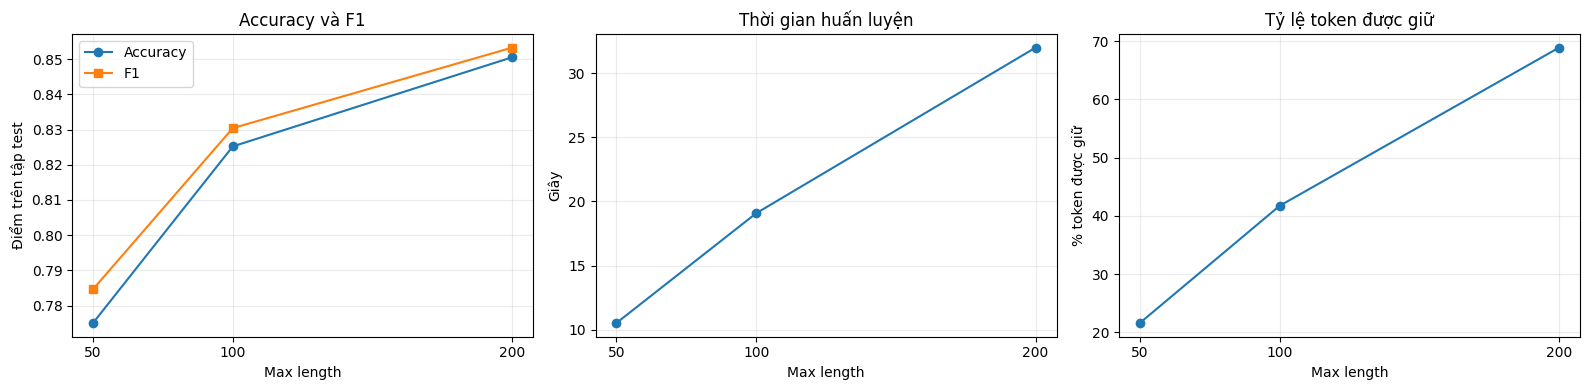

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(experiment_2_results['Max length'], experiment_2_results['Accuracy'], 'o-', label='Accuracy')
axes[0].plot(experiment_2_results['Max length'], experiment_2_results['F1'], 's-', label='F1')
axes[0].set_ylabel('Điểm trên tập test')
axes[0].legend()
axes[1].plot(experiment_2_results['Max length'], experiment_2_results['Training time (s)'], 'o-')
axes[1].set_ylabel('Giây')
axes[2].plot(experiment_2_results['Max length'], experiment_2_results['% tokens retained'], 'o-')
axes[2].set_ylabel('% token được giữ')
for ax in axes:
    ax.set_xlabel('Max length')
    ax.set_xticks(max_lengths)
    ax.grid(alpha=0.25)
axes[0].set_title('Accuracy và F1')
axes[1].set_title('Thời gian huấn luyện')
axes[2].set_title('Tỷ lệ token được giữ')
plt.tight_layout()
plt.show()


## 2.6. Review bị ảnh hưởng bởi truncation

Bốn review IMDb dưới đây được chọn vì có từ chỉ cảm xúc, phủ định hoặc nhận xét đối lập ở gần cuối. Vị trí token tính từ 0 theo đúng `token_pattern`. Cột "Bị cắt" cho biết dấu hiệu cụ thể đó có bị mất ở từng ngưỡng hay không; đây là ví dụ về **thông tin văn bản**, không phải khẳng định mô hình đã dự đoán sai.


In [18]:
selected_reviews = [
    (308, 71, 'not', 'phủ định cuối bài'),
    (21, 176, 'but', 'nhận xét đối lập cuối bài'),
    (7, 164, 'awful', 'từ chỉ cảm xúc tiêu cực'),
    (216, 222, 'excellent', 'kết luận tích cực'),
]
example_rows = []
for review_id, position, marker, role in selected_reviews:
    words = token_pattern.findall(df.iloc[review_id]['review_clean'])
    assert words[position] == marker, f'Review {review_id} đã thay đổi; chọn lại ví dụ.'
    for max_length in max_lengths:
        example_rows.append({
            'Review ID': review_id,
            'Nhãn': df.iloc[review_id]['sentiment'],
            'Dấu hiệu': f'{marker} (token {position}, {role})',
            'Đoạn cuối gốc': ' '.join(words[-45:]),
            'Max length': max_length,
            'Văn bản được giữ': ' '.join(words[:max_length]),
            'Dấu hiệu bị cắt': position >= max_length,
        })
truncation_examples = pd.DataFrame(example_rows)
with pd.option_context('display.max_colwidth', None, 'display.max_rows', None):
    display(truncation_examples)


,Review ID,Nhãn,Dấu hiệu,Đoạn cuối gốc,Max length,Văn bản được giữ,Dấu hiệu bị cắt
0,308,negative,"not (token 71, phủ định cuối bài)",inventive and there's a cool scene where two characters are falling from a skyscraper one that has to be several miles high but overall there's not much to recommend kite watch it if you want but you're not missing much if you skip this one,50,well there's no real plot to speak of it's just an excuse to show some scenes of extreme violence and gratuitous sex which can sometimes be fun too but it's not in this case what else can i say about this the action when happening is inventive and there's a,True
1,308,negative,"not (token 71, phủ định cuối bài)",inventive and there's a cool scene where two characters are falling from a skyscraper one that has to be several miles high but overall there's not much to recommend kite watch it if you want but you're not missing much if you skip this one,100,well there's no real plot to speak of it's just an excuse to show some scenes of extreme violence and gratuitous sex which can sometimes be fun too but it's not in this case what else can i say about this the action when happening is inventive and there's a cool scene where two characters are falling from a skyscraper one that has to be several miles high but overall there's not much to recommend kite watch it if you want but you're not missing much if you skip this one,False
2,308,negative,"not (token 71, phủ định cuối bài)",inventive and there's a cool scene where two characters are falling from a skyscraper one that has to be several miles high but overall there's not much to recommend kite watch it if you want but you're not missing much if you skip this one,200,well there's no real plot to speak of it's just an excuse to show some scenes of extreme violence and gratuitous sex which can sometimes be fun too but it's not in this case what else can i say about this the action when happening is inventive and there's a cool scene where two characters are falling from a skyscraper one that has to be several miles high but overall there's not much to recommend kite watch it if you want but you're not missing much if you skip this one,False
3,21,negative,"but (token 176, nhận xét đối lập cuối bài)",old wrinkled thing that comes in towards the end they try to appear sexy in those weird horrible costumes and they fail miserably even some of the most ridiculous b movies will still give you some laughs but this is just too painful to watch,50,i had the terrible misfortune of having to view this b movie in it's entirety all i have to say is save your time and money this has got to be the worst b movie of all time it shouldn't even be called a b movie more like an f,True
4,21,negative,"but (token 176, nhận xét đối lập cuối bài)",old wrinkled thing that comes in towards the end they try to appear sexy in those weird horrible costumes and they fail miserably even some of the most ridiculous b movies will still give you some laughs but this is just too painful to watch,100,i had the terrible misfortune of having to view this b movie in it's entirety all i have to say is save your time and money this has got to be the worst b movie of all time it shouldn't even be called a b movie more like an f movie because it fails in all aspects that make a good movie the story is not interesting at all all of the actors are paper thin and not at all believable it has bad direction and the action sequences are so fake it's almost funny almost the movie is just,True
5,21,negative,"but (token 176, nhận xét đối lập cuối bài)",old wrinkled thing that comes in towards the end they try to appear sexy in those weird horrible costumes and they fail miserably even some of the most ridiculous b movies will still give you some laughs but this is just too painful to watch,200,i had the terrible misfortune of having to view this b movie in it's entirety all i have to say is save your time and money this has got to be the worst b movie of all time

## Kết luận Experiment 2

**Câu 1 — Tăng `max_length` có luôn làm hiệu năng tốt hơn không?** Chưa thể kết luận bằng số liệu khi chưa chạy ba lần huấn luyện. Sau khi chạy, điền từ `experiment_2_results`: Accuracy/F1 ở 50, 100, 200 lần lượt là **[chưa chạy] / [chưa chạy] / [chưa chạy]**; thời gian huấn luyện là **[chưa chạy] / [chưa chạy] / [chưa chạy] giây**; tỷ lệ token giữ lại là **[chưa chạy] / [chưa chạy] / [chưa chạy]%**. So sánh trực tiếp từng cặp: nếu điểm giảm hoặc không đổi dù giữ nhiều token hơn, dữ liệu này bác bỏ nhận định "luôn tốt hơn". Chuỗi dài hơn cũng làm BPTT tốn thời gian hơn và có thể khó học phụ thuộc xa.

**Câu 2 — `max_length` quá nhỏ làm mất gì?** Có thể mất từ chỉ cảm xúc (`awful`, `excellent`), phủ định (`not`), phần chuyển ý (`but`) và kết luận ở cuối review. Bảng ví dụ phía trên chỉ rõ token nào bị cắt tại 50/100/200; mất các từ này có thể đổi cách hiểu sắc thái, nhưng tác động đến dự đoán phải đối chiếu với kết quả mô hình thực tế.


# Experiment 3 - Baseline

## 3.1 Experiment Setup

Dùng lại `train_idx`, `val_idx`, `test_idx`, `token_pattern`, `vocab` và `pad_post` của Experiment 2. LAB 04 dùng TF-IDF unigram + bigram (`max_features=1000`, `sublinear_tf=True`) và Logistic Regression, nhưng kết quả lưu ở đó dùng dữ liệu đã xóa trùng lặp và một phép chia khác; vì vậy phải huấn luyện lại trên đúng các chỉ số của notebook này. Cả hai mô hình nhận cùng văn bản `review_clean` sau khi chuẩn hóa thành chuỗi token theo `token_pattern`. Giữ phép chia gốc, nhưng loại khỏi validation/test các review trùng nội dung với tập trước để tránh rò rỉ văn bản; cả hai mô hình dùng đúng cùng các chỉ số còn lại. Validation chỉ để theo dõi; test chỉ đánh giá sau huấn luyện.


In [19]:
import random
import textwrap
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score
from IPython.display import Markdown

EXP3_SEED = SEED
EXP3_MAX_LENGTH = 100
EXP3_EMBEDDING_DIM = EMBEDDING_DIM
EXP3_HIDDEN_SIZE = HIDDEN_SIZE
EXP3_BATCH_SIZE = BATCH_SIZE
EXP3_EPOCHS = EPOCHS
EXP3_LEARNING_RATE = LEARNING_RATE

random.seed(EXP3_SEED)
np.random.seed(EXP3_SEED)
torch.manual_seed(EXP3_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(EXP3_SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Cùng một chuỗi token cho cả hai mô hình và các phép hoán vị phía dưới.
exp3_texts = df['review_clean'].map(
    lambda text: ' '.join(token_pattern.findall(text))
)
exp3_labels = labels.astype(np.int64)
# Giữ phân hoạch gốc nhưng bỏ các bản sao văn bản xuyên tập.
exp3_train_idx = train_idx.copy()
train_text_set_3 = set(exp3_texts.iloc[exp3_train_idx])
exp3_val_idx = val_idx[
    ~exp3_texts.iloc[val_idx].isin(train_text_set_3).to_numpy()
]
val_text_set_3 = set(exp3_texts.iloc[exp3_val_idx])
exp3_test_idx = test_idx[
    ~exp3_texts.iloc[test_idx].isin(train_text_set_3 | val_text_set_3).to_numpy()
]
assert not set(exp3_texts.iloc[exp3_train_idx]) & set(exp3_texts.iloc[exp3_val_idx])
assert not set(exp3_texts.iloc[exp3_train_idx]) & set(exp3_texts.iloc[exp3_test_idx])
assert not set(exp3_texts.iloc[exp3_val_idx]) & set(exp3_texts.iloc[exp3_test_idx])
assert np.array_equal(
    np.sort(np.concatenate([train_idx, val_idx, test_idx])), np.arange(len(df))
)
print(f'Thiết bị: {device}; train/validation/test sau lọc trùng: '
      f'{len(exp3_train_idx)}/{len(exp3_val_idx)}/{len(exp3_test_idx)}')


Thiết bị: cuda; train/validation/test sau lọc trùng: 36000/3959/9855


## 3.2 TF-IDF + Logistic Regression Baseline

Giữ cấu hình phân loại gốc của LAB 04. `Pipeline.fit` chỉ thấy train; vectorizer đã fit mới được dùng cho validation và test. Vì `ngram_range=(1, 2)`, baseline có thể phản ứng với thay đổi thứ tự ở phạm vi bigram.


In [20]:
baseline = Pipeline([
    ('tfidf', TfidfVectorizer(
        lowercase=True, max_features=1000, ngram_range=(1, 2),
        sublinear_tf=True,
    )),
    ('lr', LogisticRegression(max_iter=10000, random_state=EXP3_SEED)),
])
start = time.perf_counter()
baseline.fit(exp3_texts.iloc[exp3_train_idx], exp3_labels[exp3_train_idx])
baseline_training_time = time.perf_counter() - start
baseline_val_features = baseline.named_steps['tfidf'].transform(
    exp3_texts.iloc[exp3_val_idx]
)
baseline_val_pred = baseline.named_steps['lr'].predict(baseline_val_features)
print(f'Baseline: validation accuracy={accuracy_score(exp3_labels[exp3_val_idx], baseline_val_pred):.4f}, '
      f'training time={baseline_training_time:.2f}s')
positive_column = int(np.flatnonzero(baseline.classes_ == 1)[0])


Baseline: validation accuracy=0.8583, training time=37.74s


## 3.3 Custom Simple RNN Architecture

`SimpleRNNCell.py` dùng NumPy nên PyTorch autograd không thể huấn luyện trực tiếp các mảng của nó. Phiên bản dưới đây giữ đúng phương trình `tanh(W_xh x_t + W_hh h_{t-1} + b_h)` bằng `nn.Parameter` và vòng lặp thời gian tường minh. `nn.Embedding` học biểu diễn token, `nn.Linear` tạo một logit cho lớp positive. Mask giữ nguyên hidden state sau token cuối thật.


In [21]:
class TorchSimpleRNNClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_ID)
        self.W_xh = nn.Parameter(torch.empty(hidden_size, embedding_dim))
        self.W_hh = nn.Parameter(torch.empty(hidden_size, hidden_size))
        self.b_h = nn.Parameter(torch.zeros(hidden_size))
        self.classifier = nn.Linear(hidden_size, 1)
        nn.init.normal_(self.embedding.weight, mean=0.0, std=0.05)
        with torch.no_grad():
            self.embedding.weight[PAD_ID].zero_()
        nn.init.xavier_uniform_(self.W_xh)
        nn.init.orthogonal_(self.W_hh)

    def forward(self, token_ids, actual_lengths):
        batch_size = token_ids.size(0)
        hidden_size = self.W_hh.size(0)
        h = torch.zeros(batch_size, hidden_size,
                        device=token_ids.device, dtype=self.embedding.weight.dtype)
        embedded = self.embedding(token_ids)
        for t in range(int(actual_lengths.max().item())):
            candidate = torch.tanh(
                F.linear(embedded[:, t, :], self.W_xh, self.b_h)
                + F.linear(h, self.W_hh)
            )
            h = torch.where((actual_lengths > t).unsqueeze(1), candidate, h)
        return self.classifier(h).squeeze(1)

train_ids_3, train_lengths_3 = pad_post(exp3_train_idx, EXP3_MAX_LENGTH)
val_ids_3, val_lengths_3 = pad_post(exp3_val_idx, EXP3_MAX_LENGTH)
test_ids_3, test_lengths_3 = pad_post(exp3_test_idx, EXP3_MAX_LENGTH)
rnn_3 = TorchSimpleRNNClassifier(
    len(vocab) + 2, EXP3_EMBEDDING_DIM, EXP3_HIDDEN_SIZE
).to(device)
print(f'RNN parameters: {sum(p.numel() for p in rnn_3.parameters()):,}')


RNN parameters: 322,113


## 3.4 Training Custom Simple RNN

Adam tối ưu binary cross entropy trên logit. Mỗi epoch ghi loss train và validation; dùng mô hình ở epoch cuối, không chọn bằng test. Thời gian cộng các vòng cập nhật trọng số, không tính validation, để so sánh với thời gian `Pipeline.fit`. Việc cố định seed giúp chạy lại gần như giống nhau; GPU vẫn có thể có sai khác nhỏ tùy phần cứng.


In [22]:
def exp3_loader(ids, lengths, targets, batch_size, shuffle=False):
    dataset = TensorDataset(
        torch.from_numpy(ids.astype(np.int64)),
        torch.from_numpy(lengths.astype(np.int64)),
        torch.from_numpy(targets.astype(np.float32)),
    )
    return DataLoader(
        dataset, batch_size=batch_size, shuffle=shuffle,
        generator=torch.Generator().manual_seed(EXP3_SEED),
    )

train_loader_3 = exp3_loader(
    train_ids_3, train_lengths_3, exp3_labels[exp3_train_idx], EXP3_BATCH_SIZE, True
)
val_loader_3 = exp3_loader(
    val_ids_3, val_lengths_3, exp3_labels[exp3_val_idx], EXP3_BATCH_SIZE
)
criterion_3 = nn.BCEWithLogitsLoss()
optimizer_3 = torch.optim.Adam(rnn_3.parameters(), lr=EXP3_LEARNING_RATE)
history_3 = []
rnn_training_time = 0.0

for epoch in range(EXP3_EPOCHS):
    rnn_3.train()
    train_loss_sum = 0.0
    if device.type == 'cuda':
        torch.cuda.synchronize()
    epoch_start = time.perf_counter()
    for batch_ids, batch_lengths, batch_y in train_loader_3:
        batch_ids = batch_ids.to(device)
        batch_lengths = batch_lengths.to(device)
        batch_y = batch_y.to(device)
        optimizer_3.zero_grad(set_to_none=True)
        logits = rnn_3(batch_ids, batch_lengths)
        loss = criterion_3(logits, batch_y)
        loss.backward()
        nn.utils.clip_grad_norm_(rnn_3.parameters(), max_norm=5.0)
        optimizer_3.step()
        train_loss_sum += loss.item() * len(batch_y)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    rnn_training_time += time.perf_counter() - epoch_start

    rnn_3.eval()
    val_loss_sum = 0.0
    with torch.no_grad():
        for batch_ids, batch_lengths, batch_y in val_loader_3:
            logits = rnn_3(batch_ids.to(device), batch_lengths.to(device))
            val_loss_sum += criterion_3(logits, batch_y.to(device)).item() * len(batch_y)
    history_3.append({
        'Epoch': epoch + 1,
        'Train loss': train_loss_sum / len(exp3_train_idx),
        'Validation loss': val_loss_sum / len(exp3_val_idx),
    })
    print(f"Epoch {epoch + 1}/{EXP3_EPOCHS}: train loss={history_3[-1]['Train loss']:.4f}, "
          f"validation loss={history_3[-1]['Validation loss']:.4f}")

training_history_3 = pd.DataFrame(history_3)
display(training_history_3)
print(f'RNN training time: {rnn_training_time:.2f}s')


Epoch 1/2: train loss=0.6440, validation loss=0.5825
Epoch 2/2: train loss=0.4453, validation loss=0.4338


,Epoch,Train loss,Validation loss
0,1,0.643964,0.582518
1,2,0.445308,0.433818


RNN training time: 24.51s


## 3.5 Model Evaluation and Comparison

Các chỉ số được tính trên cùng `exp3_test_idx` sau khi lọc trùng, với ngưỡng positive là 0,5. Precision, Recall và F1 dùng lớp positive làm lớp đích cho cả hai mô hình. Không dùng test để chọn cấu hình.


,Model,Representation,Accuracy,Precision,Recall,F1,Training time (s)
0,Logistic Regression,TF-IDF,0.861898,0.859628,0.869774,0.864671,37.736906
1,Custom Simple RNN,Embedding,0.812278,0.796014,0.846969,0.820702,24.506275


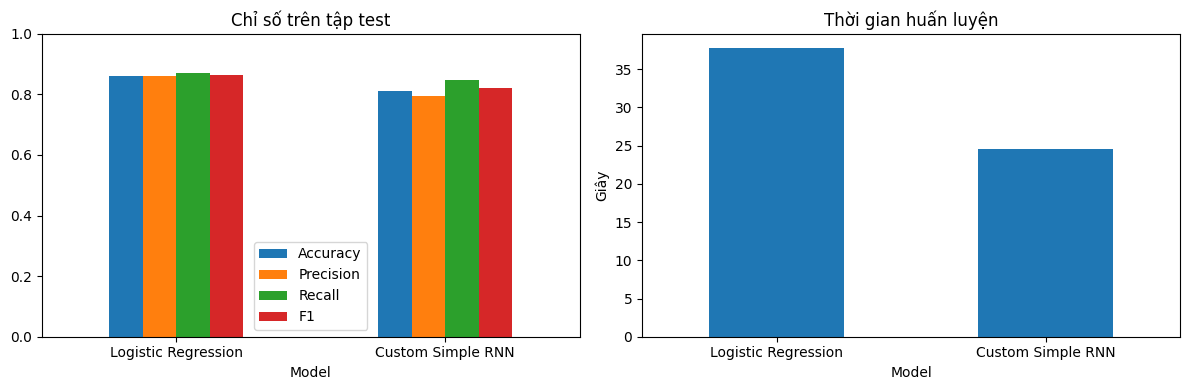

In [23]:
def predict_rnn_probabilities(ids, lengths):
    rnn_3.eval()
    probabilities = []
    with torch.no_grad():
        for start in range(0, len(ids), EXP3_BATCH_SIZE):
            batch_ids = torch.from_numpy(
                ids[start:start + EXP3_BATCH_SIZE].astype(np.int64)
            ).to(device)
            batch_lengths = torch.from_numpy(
                lengths[start:start + EXP3_BATCH_SIZE].astype(np.int64)
            ).to(device)
            probabilities.append(torch.sigmoid(
                rnn_3(batch_ids, batch_lengths)
            ).cpu().numpy())
    return np.concatenate(probabilities)

def exp3_metrics(y_true, positive_probabilities):
    predicted = (positive_probabilities >= 0.5).astype(np.int64)
    return {
        'Accuracy': accuracy_score(y_true, predicted),
        'Precision': precision_score(y_true, predicted, pos_label=1, zero_division=0),
        'Recall': recall_score(y_true, predicted, pos_label=1, zero_division=0),
        'F1': f1_score(y_true, predicted, pos_label=1, zero_division=0),
    }

baseline_test_probs = baseline.predict_proba(exp3_texts.iloc[exp3_test_idx])[:, positive_column]
rnn_test_probs = predict_rnn_probabilities(test_ids_3, test_lengths_3)
model_comparison_3 = pd.DataFrame([
    {'Model': 'Logistic Regression', 'Representation': 'TF-IDF',
     **exp3_metrics(exp3_labels[exp3_test_idx], baseline_test_probs),
     'Training time (s)': baseline_training_time},
    {'Model': 'Custom Simple RNN', 'Representation': 'Embedding',
     **exp3_metrics(exp3_labels[exp3_test_idx], rnn_test_probs),
     'Training time (s)': rnn_training_time},
])
display(model_comparison_3)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
model_comparison_3.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1']].plot(
    kind='bar', ax=axes[0], rot=0, ylim=(0, 1)
)
axes[0].set_title('Chỉ số trên tập test')
model_comparison_3.plot.bar(
    x='Model', y='Training time (s)', ax=axes[1], rot=0, legend=False
)
axes[1].set_title('Thời gian huấn luyện')
axes[1].set_ylabel('Giây')
plt.tight_layout()
plt.show()


## 3.6 Sequence Sensitivity — Word Order Permutation

Các cặp có cùng **đa tập token** nhưng thay đổi vị trí từ. Cả hai câu đi qua cùng bước làm sạch và token hóa như train; không cắt token. Baseline LAB 04 chứa bigram nên không bất biến với hoán vị như TF-IDF chỉ dùng unigram.


In [24]:
def canonicalize_exp3(text):
    cleaned = re.sub(r'<[^>]+>', ' ', html.unescape(text)).strip().lower()
    return ' '.join(token_pattern.findall(cleaned))

def encode_texts_exp3(texts):
    ids = np.full((len(texts), EXP3_MAX_LENGTH), PAD_ID, dtype=np.int32)
    lengths = np.empty(len(texts), dtype=np.int32)
    for row, text in enumerate(texts):
        tokens = token_pattern.findall(text)
        assert len(tokens) <= EXP3_MAX_LENGTH, 'Câu kiểm tra bị truncation.'
        sequence = [vocab.get(token, UNK_ID) for token in tokens]
        lengths[row] = len(sequence)
        ids[row, :len(sequence)] = sequence
    return ids, lengths

sentence_pairs_3 = [
    ('The movie was good but the ending was terrible',
     'The movie was terrible but the ending was good'),
    ('The acting was excellent but the plot was awful',
     'The acting was awful but the plot was excellent'),
    ('The film is not good', 'The film is good not'),
]
pair_texts_3 = []
for first, second in sentence_pairs_3:
    first, second = canonicalize_exp3(first), canonicalize_exp3(second)
    assert Counter(first.split()) == Counter(second.split())
    assert max(len(first.split()), len(second.split())) <= EXP3_MAX_LENGTH
    pair_texts_3.extend([first, second])
pair_ids_3, pair_lengths_3 = encode_texts_exp3(pair_texts_3)
pair_baseline_probs = baseline.predict_proba(pair_texts_3)[:, positive_column]
pair_rnn_probs = predict_rnn_probabilities(pair_ids_3, pair_lengths_3)
pair_rows_3 = []
for pair_number in range(len(sentence_pairs_3)):
    for version, row in [('A', pair_number * 2), ('B', pair_number * 2 + 1)]:
        for model_name, probabilities in [
            ('Logistic Regression', pair_baseline_probs),
            ('Custom Simple RNN', pair_rnn_probs),
        ]:
            probability = float(probabilities[row])
            pair_rows_3.append({
                'Pair': pair_number + 1, 'Version': version,
                'Sentence': pair_texts_3[row], 'Model': model_name,
                'Prediction': 'positive' if probability >= 0.5 else 'negative',
                'Positive probability': probability,
            })
pair_results_3 = pd.DataFrame(pair_rows_3)
display(pair_results_3)


,Pair,Version,Sentence,Model,Prediction,Positive probability
0,1,A,the movie was good but the ending was terrible,Logistic Regression,negative,0.057927
1,1,A,the movie was good but the ending was terrible,Custom Simple RNN,negative,0.277631
2,1,B,the movie was terrible but the ending was good,Logistic Regression,negative,0.057927
3,1,B,the movie was terrible but the ending was good,Custom Simple RNN,negative,0.156091
4,2,A,the acting was excellent but the plot was awful,Logistic Regression,negative,0.110598
5,2,A,the acting was excellent but the plot was awful,Custom Simple RNN,negative,0.283535
6,2,B,the acting was awful but the plot was excellent,Logistic Regression,negative,0.110598
7,2,B,the acting was awful but the plot was excellent,Custom Simple RNN,negative,0.118828
8,3,A,the film is not good,Logistic Regression,negative,0.455358
9,3,A,the film is not good,Custom Simple RNN,positive,0.582874


## 3.7 Quantitative Sequence Sensitivity

Lấy tối đa 200 review test có 8–100 token để cả câu gốc lẫn câu đảo đều không bị cắt. Seed cố định quyết định mẫu và thứ tự đảo. Hoán vị giữ nguyên số lần xuất hiện của từng token, nhưng có thể tạo câu thiếu tự nhiên. Bảng đo tỷ lệ nhãn đổi và trung bình `|p_gốc − p_đảo|` của lớp positive.


Số review được hoán vị: 200


,Model,Prediction change rate,Mean probability change
0,Logistic Regression,0.085,0.055272
1,Custom Simple RNN,0.070,0.058949


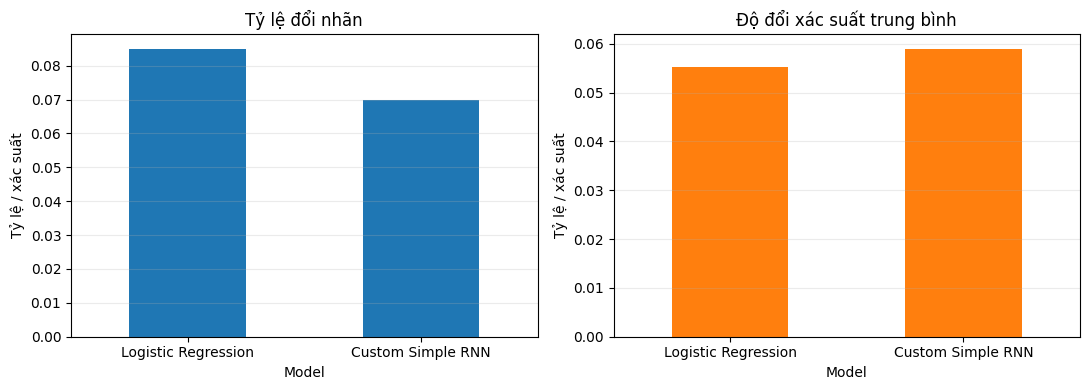

In [25]:
eligible_3 = exp3_test_idx[
    (original_lengths[exp3_test_idx] >= 8)
    & (original_lengths[exp3_test_idx] <= EXP3_MAX_LENGTH)
]
assert len(eligible_3) > 0, 'Không có review test đủ ngắn để hoán vị.'
shuffle_rng_3 = np.random.default_rng(EXP3_SEED)
sample_idx_3 = shuffle_rng_3.choice(
    eligible_3, size=min(200, len(eligible_3)), replace=False
)
original_texts_3 = exp3_texts.iloc[sample_idx_3].tolist()
shuffled_texts_3 = []
for text in original_texts_3:
    tokens = text.split()
    shuffled = shuffle_rng_3.permutation(tokens).tolist()
    if shuffled == tokens and len(set(tokens)) > 1:
        shuffled = tokens[1:] + tokens[:1]
    shuffled_texts_3.append(' '.join(shuffled))
assert all(Counter(a.split()) == Counter(b.split())
           for a, b in zip(original_texts_3, shuffled_texts_3))
assert all(len(text.split()) <= EXP3_MAX_LENGTH for text in shuffled_texts_3)

original_ids_3, original_lengths_3 = pad_post(sample_idx_3, EXP3_MAX_LENGTH)
shuffled_ids_3, shuffled_lengths_3 = encode_texts_exp3(shuffled_texts_3)
assert np.array_equal(original_lengths_3, shuffled_lengths_3)
assert np.array_equal(original_ids_3, encode_texts_exp3(original_texts_3)[0])

sequence_probabilities_3 = {
    'Logistic Regression': (
        baseline.predict_proba(original_texts_3)[:, positive_column],
        baseline.predict_proba(shuffled_texts_3)[:, positive_column],
    ),
    'Custom Simple RNN': (
        predict_rnn_probabilities(original_ids_3, original_lengths_3),
        predict_rnn_probabilities(shuffled_ids_3, shuffled_lengths_3),
    ),
}
sensitivity_rows_3 = []
for model_name, (original_probs, shuffled_probs) in sequence_probabilities_3.items():
    sensitivity_rows_3.append({
        'Model': model_name,
        'Prediction change rate': np.mean(
            (original_probs >= 0.5) != (shuffled_probs >= 0.5)
        ),
        'Mean probability change': np.mean(np.abs(original_probs - shuffled_probs)),
    })
sequence_sensitivity_3 = pd.DataFrame(sensitivity_rows_3)
print(f'Số review được hoán vị: {len(sample_idx_3)}')
display(sequence_sensitivity_3)
axes = sequence_sensitivity_3.set_index('Model')[
    ['Prediction change rate', 'Mean probability change']
].plot(kind='bar', subplots=True, layout=(1, 2), figsize=(11, 4), rot=0,
       legend=False, title=['Tỷ lệ đổi nhãn', 'Độ đổi xác suất trung bình'])
for ax in np.ravel(axes):
    ax.set_ylabel('Tỷ lệ / xác suất')
    ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


## 3.8 Results and Discussion

### Experiment 3 — Results and Discussion

**Trước khi chạy:** chưa có số liệu để kết luận mô hình nào tốt hơn hoặc nhạy với thứ tự hơn. Cell tiếp theo tạo phần thảo luận bằng tiếng Việt trực tiếp từ bảng so sánh, các cặp đảo từ và phép hoán vị trên tập test; không dùng số liệu LAB 04 vì tập test khác. Việc bỏ review trùng xuyên tập làm kích thước test nhỏ hơn Experiment 2.

Về lý thuyết, hidden state của RNN phụ thuộc vào các token đứng trước. TF-IDF unigram không biểu diễn thứ tự; baseline đang dùng thêm bigram nên vẫn giữ một phần thứ tự cục bộ. Độ nhạy khi đảo từ không tự chứng minh mô hình hiểu nghĩa. Các câu đảo có thể kém tự nhiên; kết quả còn chịu ảnh hưởng của giới hạn 100 token, tối ưu hóa RNN và nguy cơ underfitting.


In [26]:
lr_result_3 = model_comparison_3.iloc[0]
rnn_result_3 = model_comparison_3.iloc[1]
lr_sensitivity_3 = sequence_sensitivity_3.iloc[0]
rnn_sensitivity_3 = sequence_sensitivity_3.iloc[1]
pair_changes_3 = {}
for model_name in ('Logistic Regression', 'Custom Simple RNN'):
    rows = pair_results_3[pair_results_3['Model'] == model_name]
    pair_changes_3[model_name] = sum(
        rows[rows['Pair'] == pair]['Prediction'].nunique() > 1
        for pair in range(1, len(sentence_pairs_3) + 1)
    )

if (rnn_sensitivity_3['Prediction change rate'] > lr_sensitivity_3['Prediction change rate']
        and rnn_sensitivity_3['Mean probability change'] > lr_sensitivity_3['Mean probability change']):
    evidence_3 = ('Trong phép đảo từ này, RNN nhạy hơn baseline theo cả hai thước đo; '
                  'đây là bằng chứng thực nghiệm về phản ứng với thứ tự, chưa chứng minh hiểu đúng nghĩa.')
else:
    evidence_3 = ('Hai thước đo chưa cùng cho thấy RNN nhạy hơn baseline; '
                  'không thể khẳng định RNN khai thác thứ tự tốt hơn từ dữ liệu này.')

display(Markdown(textwrap.dedent(f"""
**Hiệu năng tổng thể (test):** Logistic Regression đạt Accuracy {lr_result_3['Accuracy']:.4f},
Precision {lr_result_3['Precision']:.4f}, Recall {lr_result_3['Recall']:.4f},
F1 {lr_result_3['F1']:.4f} trong {lr_result_3['Training time (s)']:.2f} giây.
RNN đạt Accuracy {rnn_result_3['Accuracy']:.4f}, Precision {rnn_result_3['Precision']:.4f},
Recall {rnn_result_3['Recall']:.4f}, F1 {rnn_result_3['F1']:.4f}
trong {rnn_result_3['Training time (s)']:.2f} giây. Chênh lệch điểm tổng thể
không tự chứng minh khả năng dùng thứ tự từ.

**Thứ tự từ:** Trong {len(sentence_pairs_3)} cặp câu có cùng đa tập token,
Logistic Regression đổi nhãn ở {pair_changes_3['Logistic Regression']} cặp,
RNN đổi nhãn ở {pair_changes_3['Custom Simple RNN']} cặp; bảng 3.6 ghi xác suất
từng câu. Trên {len(sample_idx_3)} review test được đảo từ, tỷ lệ đổi nhãn và
độ đổi xác suất trung bình lần lượt là
{lr_sensitivity_3['Prediction change rate']:.3f} / {lr_sensitivity_3['Mean probability change']:.3f}
cho Logistic Regression, so với
{rnn_sensitivity_3['Prediction change rate']:.3f} / {rnn_sensitivity_3['Mean probability change']:.3f}
cho RNN. {evidence_3}

**Giải thích và giới hạn:** Phương trình recurrent làm hidden state phụ thuộc vào
các token trước đó; TF-IDF unigram bỏ thứ tự, nhưng bigram trong baseline có thể
nhận biết thứ tự cục bộ. Do đó không thể nói mọi TF-IDF đều không biểu diễn thứ tự.
Hoán vị toàn câu tạo câu thiếu tự nhiên; mẫu {len(sample_idx_3)} review,
truncation 100 token, hai epoch huấn luyện và khả năng underfitting giới hạn
độ mạnh của kết luận. Nếu xác suất hoặc nhãn ít đổi, kết quả chỉ ra rằng mô hình
RNN **đã huấn luyện ở đây** chưa thể hiện rõ độ nhạy, dù kiến trúc có khả năng đó.
""")))



**Hiệu năng tổng thể (test):** Logistic Regression đạt Accuracy 0.8619,
Precision 0.8596, Recall 0.8698,
F1 0.8647 trong 37.74 giây.
RNN đạt Accuracy 0.8123, Precision 0.7960,
Recall 0.8470, F1 0.8207
trong 24.51 giây. Chênh lệch điểm tổng thể
không tự chứng minh khả năng dùng thứ tự từ.

**Thứ tự từ:** Trong 3 cặp câu có cùng đa tập token,
Logistic Regression đổi nhãn ở 1 cặp,
RNN đổi nhãn ở 0 cặp; bảng 3.6 ghi xác suất
từng câu. Trên 200 review test được đảo từ, tỷ lệ đổi nhãn và
độ đổi xác suất trung bình lần lượt là
0.085 / 0.055
cho Logistic Regression, so với
0.070 / 0.059
cho RNN. Hai thước đo chưa cùng cho thấy RNN nhạy hơn baseline; không thể khẳng định RNN khai thác thứ tự tốt hơn từ dữ liệu này.

**Giải thích và giới hạn:** Phương trình recurrent làm hidden state phụ thuộc vào
các token trước đó; TF-IDF unigram bỏ thứ tự, nhưng bigram trong baseline có thể
nhận biết thứ tự cục bộ. Do đó không thể nói mọi TF-IDF đều không biểu diễn thứ tự.
Hoán vị toàn câu tạo câu thiếu tự nhiên; mẫu 200 review,
truncation 100 token, hai epoch huấn luyện và khả năng underfitting giới hạn
độ mạnh của kết luận. Nếu xác suất hoặc nhãn ít đổi, kết quả chỉ ra rằng mô hình
RNN **đã huấn luyện ở đây** chưa thể hiện rõ độ nhạy, dù kiến trúc có khả năng đó.


# Experiment 4 - RNN vs LSTM vs GRU


## 4.1 Initial Predictions

**H1 — Chất lượng phân loại:** LSTM và GRU có thể giữ thông tin xa tốt hơn Vanilla RNN nhờ cơ chế cổng; vì vậy có thể đạt Accuracy/F1 cao hơn. Không giả định LSTM luôn thắng GRU.

**H2 — Chi phí tính toán:** Với cùng kích thước ẩn, dự đoán số tham số là RNN < GRU < LSTM. Thời gian chạy và bộ nhớ thực tế còn tùy backend/phần cứng, nên thứ tự này cần đo.

**H3 — Hành vi học:** Loss validation của LSTM/GRU có thể ổn định hơn. Một đường loss mượt trong thí nghiệm ngắn không chứng minh đã giải quyết vanishing gradient.


## 4.2 Experiment Configuration

Dùng cùng cấu hình cho cả ba kiến trúc. Kích thước embedding/hidden và độ dài 100 tái sử dụng Experiment 3; batch 64, một layer, một chiều và 5 epoch giữ mức sử dụng VRAM thấp. Khác biệt tham số phát sinh tự nhiên từ số cổng của từng cell, không ép bằng nhau.


In [ ]:
import gc
from contextlib import nullcontext
from torch.nn.utils.rnn import pack_padded_sequence

EXP4_CONFIG = {
    'embedding_dim': EXP3_EMBEDDING_DIM,
    'hidden_size': EXP3_HIDDEN_SIZE,
    'num_layers': 1,
    'dropout': 0.0,
    'bidirectional': False,
    'batch_size': 64,
    'max_length': EXP3_MAX_LENGTH,
    'epochs': 5,
    'learning_rate': EXP3_LEARNING_RATE,
    'weight_decay': 0.0,
    'random_seed': EXP3_SEED,
    'num_workers': 0,
    'gradient_clip_norm': 1.0,
}
EXP4_MODEL_TYPES = ['RNN', 'LSTM', 'GRU']
EXP4_DEVICE = device
EXP4_USE_AMP = EXP4_DEVICE.type == 'cuda'
print(f"Device: {EXP4_DEVICE}; AMP: {EXP4_USE_AMP}; config: {EXP4_CONFIG}")


## 4.3 Dataset and DataLoader Preparation

Tái sử dụng từ vựng, tokenizer và các chỉ số đã tạo ở Experiment 2–3. Các review trùng văn bản xuyên train/validation/test đã được lọc trong `exp3_*_idx`; không fit lại từ vựng. Padding/cắt sau chuỗi về cùng 100 token, còn độ dài thật được đưa vào `pack_padded_sequence` để bỏ qua PAD. Dataset nằm trên CPU; chỉ batch hiện tại được chuyển lên GPU.


In [ ]:
exp4_train_ids, exp4_train_lengths = pad_post(
    exp3_train_idx, EXP4_CONFIG['max_length']
)
exp4_val_ids, exp4_val_lengths = pad_post(
    exp3_val_idx, EXP4_CONFIG['max_length']
)
exp4_test_ids, exp4_test_lengths = pad_post(
    exp3_test_idx, EXP4_CONFIG['max_length']
)

def make_exp4_dataset(ids, lengths, targets):
    return TensorDataset(
        torch.from_numpy(ids.astype(np.int64, copy=False)),
        torch.from_numpy(lengths.astype(np.int64, copy=False)),
        torch.from_numpy(targets.astype(np.float32, copy=False)),
    )

exp4_train_dataset = make_exp4_dataset(
    exp4_train_ids, exp4_train_lengths, exp3_labels[exp3_train_idx]
)
exp4_val_dataset = make_exp4_dataset(
    exp4_val_ids, exp4_val_lengths, exp3_labels[exp3_val_idx]
)
exp4_test_dataset = make_exp4_dataset(
    exp4_test_ids, exp4_test_lengths, exp3_labels[exp3_test_idx]
)
print(f"Train/validation/test: {len(exp4_train_dataset)}/"
      f"{len(exp4_val_dataset)}/{len(exp4_test_dataset)}")


## 4.4 Recurrent Classifier Architecture

Một lớp `RecurrentClassifier` dùng chung embedding, recurrent input/output shape và linear head. Chỉ lớp recurrent thay đổi giữa `nn.RNN(tanh)`, `nn.LSTM` và `nn.GRU`. Với LSTM, phần phân loại lấy `h_n` (hidden state), không dùng `c_n` (cell state). `h_n[-1]` là trạng thái hợp lệ cuối của mỗi chuỗi đã pack.


In [ ]:
class RecurrentClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_size, num_classes,
                 model_type='RNN', padding_idx=0, num_layers=1,
                 dropout=0.0, bidirectional=False):
        super().__init__()
        model_type = model_type.upper()
        if model_type not in {'RNN', 'LSTM', 'GRU'}:
            raise ValueError(f'Unsupported model_type: {model_type}')
        self.model_type = model_type
        self.num_directions = 2 if bidirectional else 1
        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=padding_idx
        )
        recurrent_args = dict(
            input_size=embedding_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
            bidirectional=bidirectional,
        )
        if model_type == 'RNN':
            self.recurrent = nn.RNN(**recurrent_args, nonlinearity='tanh')
        elif model_type == 'LSTM':
            self.recurrent = nn.LSTM(**recurrent_args)
        else:
            self.recurrent = nn.GRU(**recurrent_args)
        self.classifier = nn.Linear(hidden_size * self.num_directions, num_classes)

    def forward(self, token_ids, actual_lengths):
        embedded = self.embedding(token_ids)
        packed = pack_padded_sequence(
            embedded,
            actual_lengths.detach().to(device='cpu', dtype=torch.int64),
            batch_first=True,
            enforce_sorted=False,
        )
        _, state = self.recurrent(packed)
        hidden = state[0] if self.model_type == 'LSTM' else state
        final_hidden = hidden[-self.num_directions:].transpose(0, 1)
        final_hidden = final_hidden.reshape(token_ids.size(0), -1)
        return self.classifier(final_hidden)

def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters()
               if parameter.requires_grad)


## 4.5 Training and Evaluation Utilities

Dùng BCEWithLogitsLoss và cùng ngưỡng 0,5 cho lớp positive ở mọi mô hình. Khi có CUDA, mixed precision FP16 được bật cùng GradScaler; CPU chạy FP32. Gradient clipping giữ ổn định cập nhật. Evaluator chuyển từng batch về CPU nên không giữ toàn bộ dự đoán trên GPU.


In [ ]:
def make_exp4_loader(dataset, shuffle=False, seed=None):
    generator = None
    if shuffle:
        generator = torch.Generator().manual_seed(
            EXP4_CONFIG['random_seed'] if seed is None else seed
        )
    return DataLoader(
        dataset,
        batch_size=EXP4_CONFIG['batch_size'],
        shuffle=shuffle,
        num_workers=EXP4_CONFIG['num_workers'],
        pin_memory=EXP4_DEVICE.type == 'cuda',
        generator=generator,
    )

def count_classification_metrics(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'Recall': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        'F1': f1_score(y_true, y_pred, pos_label=1, zero_division=0),
    }

def train_one_epoch(model, dataloader, optimizer, criterion, scaler, device, use_amp):
    model.train()
    loss_sum = torch.zeros((), device=device)
    sample_count = 0
    for token_ids, lengths, targets in dataloader:
        token_ids = token_ids.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        amp_context = (
            torch.autocast(device_type='cuda', dtype=torch.float16)
            if use_amp else nullcontext()
        )
        with amp_context:
            logits = model(token_ids, lengths)
            loss = criterion(logits.squeeze(1), targets)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), EXP4_CONFIG['gradient_clip_norm'])
        scaler.step(optimizer)
        scaler.update()
        batch_size = len(targets)
        loss_sum += loss.detach().float() * batch_size
        sample_count += batch_size
    return (loss_sum / sample_count).item()

def evaluate_model(model, dataloader, criterion, device, use_amp=False):
    model.eval()
    loss_sum = torch.zeros((), device=device)
    sample_count = 0
    y_true, y_pred = [], []
    with torch.inference_mode():
        for token_ids, lengths, targets in dataloader:
            token_ids = token_ids.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)
            amp_context = (
                torch.autocast(device_type='cuda', dtype=torch.float16)
                if use_amp else nullcontext()
            )
            with amp_context:
                logits = model(token_ids, lengths).squeeze(1)
                loss = criterion(logits, targets)
            probabilities = torch.sigmoid(logits)
            loss_sum += loss.float() * len(targets)
            sample_count += len(targets)
            y_true.extend(targets.to(torch.int64).cpu().tolist())
            y_pred.extend((probabilities >= 0.5).to(torch.int64).cpu().tolist())
    return (loss_sum / sample_count).item(), count_classification_metrics(y_true, y_pred)


## 4.6 Training RNN, LSTM, and GRU

Chạy tuần tự, khởi tạo seed và DataLoader shuffle như nhau cho từng mô hình. Chọn checkpoint theo F1 validation cao nhất; test chỉ chạy sau khi khôi phục checkpoint. Timer bao gồm train và validation mỗi epoch, đồng bộ CUDA ở hai đầu, nhưng không gồm tiền xử lý hoặc test inference. Peak memory reset sau khi tạo model để ghi đỉnh allocated trong lúc huấn luyện.


In [ ]:
def train_model(model_type, train_dataset, val_dataset, test_dataset):
    seed = EXP4_CONFIG['random_seed']
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.cuda.empty_cache()

    model = RecurrentClassifier(
        vocab_size=len(vocab) + 2,
        embedding_dim=EXP4_CONFIG['embedding_dim'],
        hidden_size=EXP4_CONFIG['hidden_size'],
        num_classes=1,
        model_type=model_type,
        padding_idx=PAD_ID,
        num_layers=EXP4_CONFIG['num_layers'],
        dropout=EXP4_CONFIG['dropout'],
        bidirectional=EXP4_CONFIG['bidirectional'],
    ).to(EXP4_DEVICE)
    parameter_count = count_parameters(model)
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=EXP4_CONFIG['learning_rate'],
        weight_decay=EXP4_CONFIG['weight_decay'],
    )
    criterion = nn.BCEWithLogitsLoss()
    scaler = torch.amp.GradScaler('cuda', enabled=EXP4_USE_AMP)
    train_loader = make_exp4_loader(train_dataset, shuffle=True, seed=seed)
    val_loader = make_exp4_loader(val_dataset)
    test_loader = make_exp4_loader(test_dataset)

    if EXP4_DEVICE.type == 'cuda':
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
    start_time = time.perf_counter()
    history = []
    best_f1 = -1.0
    best_epoch = 0
    best_state = None
    for epoch in range(1, EXP4_CONFIG['epochs'] + 1):
        train_loss = train_one_epoch(
            model, train_loader, optimizer, criterion, scaler,
            EXP4_DEVICE, EXP4_USE_AMP,
        )
        val_loss, val_metrics = evaluate_model(
            model, val_loader, criterion, EXP4_DEVICE, EXP4_USE_AMP
        )
        history.append({
            'Epoch': epoch,
            'Train loss': train_loss,
            'Validation loss': val_loss,
            'Validation F1': val_metrics['F1'],
        })
        print(f"{model_type} epoch {epoch}/{EXP4_CONFIG['epochs']}: "
              f"train_loss={train_loss:.4f}, val_loss={val_loss:.4f}, "
              f"val_F1={val_metrics['F1']:.4f}")
        if val_metrics['F1'] > best_f1:
            best_f1 = val_metrics['F1']
            best_epoch = epoch
            best_state = {
                name: value.detach().cpu().clone()
                for name, value in model.state_dict().items()
            }

    if EXP4_DEVICE.type == 'cuda':
        torch.cuda.synchronize()
    training_time = time.perf_counter() - start_time
    peak_memory_mb = (
        torch.cuda.max_memory_allocated() / (1024 ** 2)
        if EXP4_DEVICE.type == 'cuda' else None
    )
    model.load_state_dict(best_state)
    _, test_metrics = evaluate_model(
        model, test_loader, criterion, EXP4_DEVICE, EXP4_USE_AMP
    )
    result = {
        'Model': model_type,
        'Parameters': parameter_count,
        'Training time (s)': training_time,
        **test_metrics,
        'Peak GPU memory (MB)': peak_memory_mb,
        'Time/Epoch (s)': training_time / EXP4_CONFIG['epochs'],
        'Best Epoch': best_epoch,
    }
    del model, optimizer, criterion, scaler, train_loader, val_loader, test_loader
    gc.collect()
    if EXP4_DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return result, history

experiment4_results = []
experiment4_histories = {}
for model_type in EXP4_MODEL_TYPES:
    result, history = train_model(
        model_type, exp4_train_dataset, exp4_val_dataset, exp4_test_dataset
    )
    experiment4_results.append(result)
    experiment4_histories[model_type] = history
    print(f"{model_type}: test F1={result['F1']:.4f}, "
          f"time={result['Training time (s)']:.2f}s, "
          f"peak CUDA memory={result['Peak GPU memory (MB)']}")


## 4.7 Model Comparison and Visualizations

Bảng chính dùng Accuracy, Precision, Recall, F1 theo cùng lớp positive. Bảng hiệu suất phần cứng hiển thị `N/A` nếu đang chạy CPU. Các biểu đồ lấy trực tiếp từ kết quả và lịch sử huấn luyện.


In [ ]:
experiment4_results_df = pd.DataFrame(experiment4_results)[[
    'Model', 'Parameters', 'Training time (s)',
    'Accuracy', 'Precision', 'Recall', 'F1',
]]
display(experiment4_results_df)

experiment4_efficiency_df = pd.DataFrame([
    {
        'Model': result['Model'],
        'Peak GPU Memory (MB)': (
            'N/A' if result['Peak GPU memory (MB)'] is None
            else round(result['Peak GPU memory (MB)'], 2)
        ),
        'Time/Epoch (s)': result['Time/Epoch (s)'],
        'Best Epoch': result['Best Epoch'],
    }
    for result in experiment4_results
])
display(experiment4_efficiency_df)

metrics_axes = experiment4_results_df.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1']
].plot(kind='bar', figsize=(9, 4), ylim=(0, 1), rot=0)
metrics_axes.set_title('So sánh chỉ số phân loại trên test')
metrics_axes.set_ylabel('Score')
metrics_axes.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for model_type, history in experiment4_histories.items():
    history_df = pd.DataFrame(history)
    axes[0].plot(history_df['Epoch'], history_df['Train loss'], marker='o',
                 label=f'{model_type} train')
    axes[1].plot(history_df['Epoch'], history_df['Validation loss'], marker='o',
                 label=f'{model_type} validation')
axes[0].set_title('Training loss')
axes[1].set_title('Validation loss')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.set_ylabel('BCE loss')
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
experiment4_results_df.plot.bar(
    x='Model', y='Training time (s)', ax=axes[0], rot=0, legend=False
)
experiment4_results_df.plot(
    x='Model', y='Parameters', kind='bar', ax=axes[1], rot=0, legend=False
)
axes[0].set_title('Tổng thời gian train + validation')
axes[0].set_ylabel('Giây')
axes[1].set_title('Số tham số có thể train')
for ax in axes:
    ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


## 4.8 Results and Discussion

### Experiment 4 — Kết quả và thảo luận

Khi chưa chạy các cell 4.6–4.7, không có số liệu thực nghiệm để xác nhận prediction. Sau khi chạy, cell tiếp theo tạo phần thảo luận tiếng Việt từ Accuracy, Precision, Recall, F1, thời gian, tham số, bộ nhớ GPU và learning curves thực tế.

Đây là so sánh với hidden size bằng nhau, không phải ngân sách tham số bằng nhau. Kết luận chỉ áp dụng cho cấu hình, split và tập IMDb này; 5 epoch và một seed chưa đủ để khái quát cho mọi tác vụ.


In [ ]:
result_by_model_4 = {row['Model']: row for row in experiment4_results}

def describe_winner_4(metric, higher_is_better=True):
    values = {name: row[metric] for name, row in result_by_model_4.items()}
    best_value = (max(values.values()) if higher_is_better else min(values.values()))
    winners = [name for name, value in values.items()
               if np.isclose(value, best_value, rtol=1e-5, atol=1e-8)]
    return f"{', '.join(winners)} ({best_value:.4f})"

parameter_order_ok = (
    result_by_model_4['RNN']['Parameters']
    < result_by_model_4['GRU']['Parameters']
    < result_by_model_4['LSTM']['Parameters']
)
rnn_val_increases = sum(
    b['Validation loss'] > a['Validation loss']
    for a, b in zip(experiment4_histories['RNN'], experiment4_histories['RNN'][1:])
)
gated_increases = [
    sum(b['Validation loss'] > a['Validation loss']
        for a, b in zip(experiment4_histories[name], experiment4_histories[name][1:]))
    for name in ('LSTM', 'GRU')
]
if all(value < rnn_val_increases for value in gated_increases):
    h3_status = 'được hỗ trợ trong các đường loss validation quan sát được'
elif any(value < rnn_val_increases for value in gated_increases):
    h3_status = 'được hỗ trợ một phần; một mô hình có cổng có ít lần loss validation tăng hơn RNN'
elif all(value == rnn_val_increases for value in gated_increases):
    h3_status = 'chưa phân định được từ số lần loss validation tăng'
else:
    h3_status = 'không được hỗ trợ bởi tiêu chí số lần loss validation tăng trong lần chạy này'

gated_improvements = {
    name: (
        result_by_model_4[name]['Accuracy'] > result_by_model_4['RNN']['Accuracy']
        and result_by_model_4[name]['F1'] > result_by_model_4['RNN']['F1']
    )
    for name in ('LSTM', 'GRU')
}
gated_ties = all(
    np.isclose(result_by_model_4[name]['Accuracy'], result_by_model_4['RNN']['Accuracy'])
    and np.isclose(result_by_model_4[name]['F1'], result_by_model_4['RNN']['F1'])
    for name in ('LSTM', 'GRU')
)
h1_status = ('được hỗ trợ' if all(gated_improvements.values()) else
             'được hỗ trợ một phần' if any(gated_improvements.values()) else
             'chưa phân định được' if gated_ties else
             'không được hỗ trợ ở Accuracy và F1 trong lần chạy này')
if parameter_order_ok:
    h2_status = 'được hỗ trợ: số tham số theo RNN < GRU < LSTM'
elif result_by_model_4['RNN']['Parameters'] < result_by_model_4['LSTM']['Parameters']:
    h2_status = 'được hỗ trợ một phần; RNN ít tham số nhất nhưng thứ tự GRU/LSTM khác dự đoán'
else:
    h2_status = 'không được hỗ trợ về thứ tự số tham số dự đoán'
h2_runtime_note = (
    'RNN nhanh nhất, phù hợp thứ tự tham số trong lần chạy này.'
    if result_by_model_4['RNN']['Training time (s)'] == min(
        result_by_model_4[name]['Training time (s)'] for name in EXP4_MODEL_TYPES
    ) else
    'Thời gian không nhất thiết theo thứ tự tham số; backend và số cổng cũng tác động.'
)
memory_available = EXP4_DEVICE.type == 'cuda'
memory_text = (
    ', '.join(f"{name}: {result_by_model_4[name]['Peak GPU memory (MB)']:.2f} MB"
              for name in EXP4_MODEL_TYPES)
    if memory_available else 'N/A (CPU)'
)
lowest_memory = (
    describe_winner_4('Peak GPU memory (MB)', higher_is_better=False)
    if memory_available else 'N/A (CPU)'
)
final_losses = ', '.join(
    f"{name}: train={experiment4_histories[name][-1]['Train loss']:.4f}, "
    f"validation={experiment4_histories[name][-1]['Validation loss']:.4f}"
    for name in EXP4_MODEL_TYPES
)

display(Markdown(f"""
**Chất lượng phân loại:** Accuracy cao nhất: {describe_winner_4('Accuracy')};
Precision cao nhất: {describe_winner_4('Precision')}; Recall cao nhất:
{describe_winner_4('Recall')}; F1 cao nhất: {describe_winner_4('F1')}.
Các metric {'cùng xếp hạng' if len({describe_winner_4(m) for m in ['Accuracy', 'Precision', 'Recall', 'F1']}) == 1 else 'không cùng xếp hạng hoàn toàn'},
nên cần cân nhắc cả cân bằng false positive/false negative thay vì chỉ Accuracy.

**Hiệu quả:** Ít tham số nhất: {describe_winner_4('Parameters', higher_is_better=False)};
train + validation nhanh nhất: {describe_winner_4('Training time (s)', higher_is_better=False)}.
Bộ nhớ GPU thấp nhất: {lowest_memory}; peak theo mô hình: {memory_text}. {h2_runtime_note}
so sánh tham số kiểm tra độ phức tạp cấu trúc, không phải ngân sách tham số bằng nhau.

**Learning behavior và predictions:** H1 {h1_status}. H2 {h2_status}.
H3 {h3_status}. Loss validation tăng ở {rnn_val_increases} chuyển epoch của RNN,
{gated_increases[0]} của LSTM và {gated_increases[1]} của GRU. Loss cuối (train/validation):
{final_losses}. Chênh lệch train/validation lớn có thể gợi ý overfitting; loss cả hai
còn cao có thể gợi ý underfitting. Đây chỉ là quan sát của 5 epoch, không chứng minh
cơ chế vanishing gradient. Kết quả có phù hợp
với prediction ban đầu hay không được đánh giá theo các status trên, không dựa riêng
vào Accuracy.

**Giới hạn:** Một seed, tối đa {EXP4_CONFIG['epochs']} epoch, hidden size
{EXP4_CONFIG['hidden_size']}, chuỗi cắt ở {EXP4_CONFIG['max_length']} token và
một dataset làm kết quả nhạy với khởi tạo/optimization, đồng thời có thể underfit.
Mô hình có nhiều cổng có số tham số khác nhau. Cần nhiều seed và cấu hình dài hơn
trước khi khái quát ra ngoài bài IMDb này.
"""))
